<a href="https://colab.research.google.com/github/cdube89128/DATA_620/blob/main/Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 - Project 2
### DATA 620
### Catherine Dube

**HW Prompt**

This project assignment is to:

* Identify a large 2-node network dataset—you can start with a dataset in a repository.
* Your data should meet the criteria that it consists of ties between and not within two (or more) distinct groups.
* Reduce the size of the network using a method such as the island method described in chapter 4 of social network analysis.
* What can you infer about each of the distinct groups?

**My HW Recap**

* I chose the [Twitch data source](https://snap.stanford.edu/data/twitch-social-networks.html) that I previously explored for a shorter homework assignment. This time I use different files from the same source, so that the data is a better fit for this project.
* I use the Portuguese-language (PTBR) streamers. Instead of the user-user friendship edges, I build a **2-mode network** from `musae_PTBR_features.json`. One set of nodes is the 1,912 streamers, and the other is the 1,449 anonymized features (derived from games played and liked, location and streaming habits). Each edge links a streamer to a feature they have, so ties only run between the two groups, never within one.
* `musae_PTBR_target.csv` adds attributes for each streamer, including whether they are a Twitch partner and their view count.

In [1]:
import glob
import json
import math
import os
import urllib.request
import zipfile

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from networkx.algorithms import bipartite
from scipy import stats

In [2]:
# Download & Extract the Twitch data
zip_filename = "twitch.zip"
data_dir = "twitch_data"

if not os.path.exists(data_dir):
  if not os.path.exists(zip_filename):
    url = "https://" + "snap.stanford.edu/data/twitch.zip"
    urllib.request.urlretrieve(url, zip_filename)

  with zipfile.ZipFile(zip_filename, "r") as zip_ref:
    zip_ref.extractall(data_dir)
  print("Extracted dataset successfully.")
else:
  print("Found existing 'twitch_data' directory.")

Extracted dataset successfully.


In [3]:
# Load 2-Mode Data (Streamers connect with Features) and Target Metadata
target_files = glob.glob(f"{data_dir}/**/musae_PTBR_target.csv", recursive=True)
features_files = glob.glob(f"{data_dir}/**/musae_PTBR_features.json", recursive=True)

target_path = target_files[0]
features_path = features_files[0]

target_df = pd.read_csv(target_path)
with open(features_path, "r") as f:
  features_data = json.load(f)

print(f"Loaded {len(target_df)} streamers from target CSV.")
print(f"Loaded {len(features_data)} user feature sets from JSON.")

Loaded 1912 streamers from target CSV.
Loaded 1912 user feature sets from JSON.


In [4]:
# Build 2-Mode (Bipartite) Graph
B = nx.Graph()

streamer_nodes = set()
feature_nodes = set()

for user_id_str, feat_list in features_data.items():
  user_id = int(user_id_str)
  streamer_node = f"user_{user_id}"
  streamer_nodes.add(streamer_node)
  B.add_node(streamer_node, bipartite=0)

  for feat in feat_list:
    feat_node = f"feat_{feat}"
    feature_nodes.add(feat_node)
    B.add_node(feat_node, bipartite=1)
    B.add_edge(streamer_node, feat_node)

print(
    f"2-Mode Bipartite Graph: {B.number_of_nodes()} total nodes"
    f" ({len(streamer_nodes)} Streamers, {len(feature_nodes)} Features),"
    f" {B.number_of_edges()} edges."
)

2-Mode Bipartite Graph: 3361 total nodes (1912 Streamers, 1449 Features), 38019 edges.


In [5]:
# Sanity checking the bipartite requirement
within_group_edges = sum(
    1 for u, v in B.edges() if (u in streamer_nodes) == (v in streamer_nodes)
)
print("Is bipartite:", nx.is_bipartite(B))
print("Edges within a group:", within_group_edges)

Is bipartite: True
Edges within a group: 0


**Checking the 2-Mode Structure**

The assignment prompt requires ties *between* the two groups and not *within* them. I did a bit of sanity checking, and every edge in `B` joins a streamer to a feature, and `nx.is_bipartite` confirms that the graph splits cleanly into the two groups with no streamer-streamer or feature-feature edges.

## Exploring the 2-Mode Network

Before projecting, I'm looking at each group's degree in the 2-mode network: how many streamers list each feature, and how many features each streamer lists.

### Feature Degrees

In [6]:
# Analyze the Second Group (Features)
# Calculate the degree for each feature to see which ones act as the biggest hubs
feature_degrees = {n: B.degree(n) for n in feature_nodes}

# Sort features by degree (highest to lowest) to find the most common ones
top_features = sorted(feature_degrees.items(), key=lambda x: x[1], reverse=True)

print("--- Top 10 Most Connected Features ---")
for feat, degree in top_features[:10]:
    print(f"{feat}: Connected to {degree} streamers")

--- Top 10 Most Connected Features ---
feat_920: Connected to 1633 streamers
feat_224: Connected to 1305 streamers
feat_3097: Connected to 1142 streamers
feat_569: Connected to 849 streamers
feat_2645: Connected to 836 streamers
feat_2424: Connected to 774 streamers
feat_2737: Connected to 759 streamers
feat_861: Connected to 739 streamers
feat_276: Connected to 603 streamers
feat_2501: Connected to 545 streamers


The feature IDs are anonymized, so I don't know what any of them actually are, and that is unfortunate in terms of sanity checking here or in terms of making sense of the most common features. Some might be popular games played, or location/region, etc.

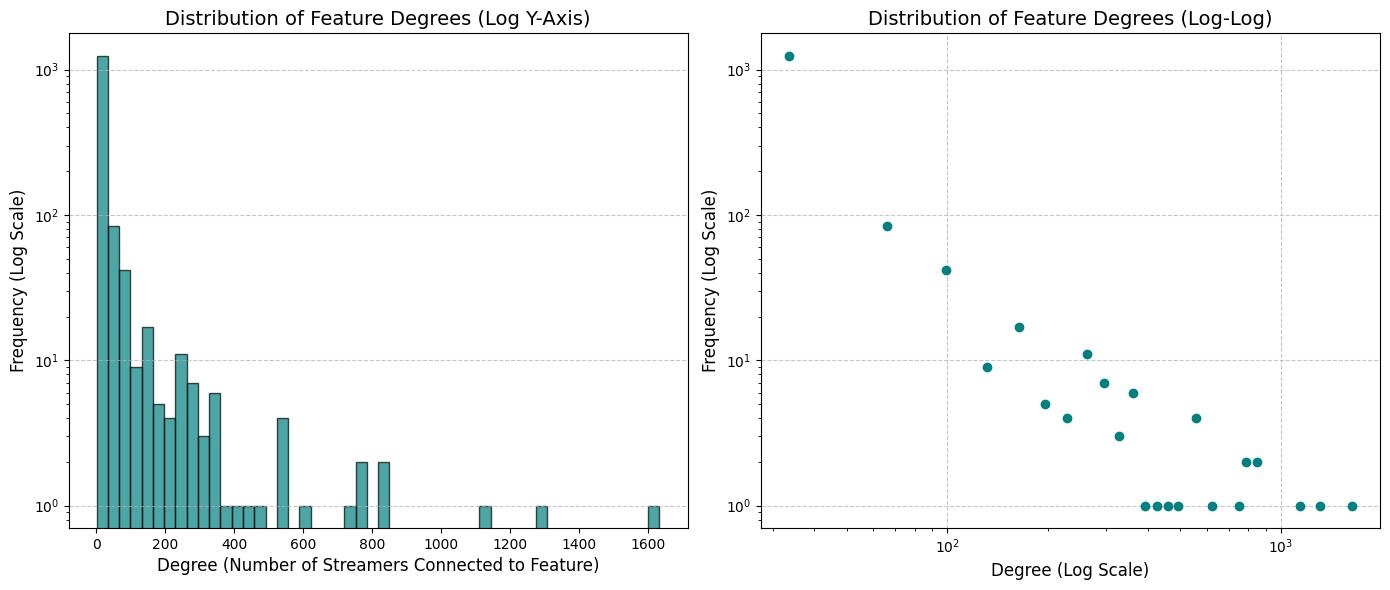

In [7]:
# Extract the degrees
degrees = list(feature_degrees.values())

# Histogram on a log y-axis, plus the same histogram in log-log space (the log-log view the book uses)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

counts, bin_edges, _ = ax1.hist(degrees, bins=50, color='teal', edgecolor='black', alpha=0.7)

# Use a log scale for the y-axis to handle the heavily skewed distribution
ax1.set_yscale('log')
ax1.set_title("Distribution of Feature Degrees (Log Y-Axis)", fontsize=14)
ax1.set_xlabel("Degree (Number of Streamers Connected to Feature)", fontsize=12)
ax1.set_ylabel("Frequency (Log Scale)", fontsize=12)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

ax2.loglog(bin_edges[1:], counts, marker='o', linestyle='none', color='teal')
ax2.set_title("Distribution of Feature Degrees (Log-Log)", fontsize=14)
ax2.set_xlabel("Degree (Log Scale)", fontsize=12)
ax2.set_ylabel("Frequency (Log Scale)", fontsize=12)
ax2.grid(linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [8]:
# Exact distribution of degrees (so I don't need to eyeball it from above)
degree_counts = pd.Series(degrees).value_counts().sort_index()

print("Total number of features:", len(feature_nodes))
print("Number of features shared by exactly 1 streamer:", degree_counts.get(1, 0))
print("Number of features shared by exactly 2 streamers:", degree_counts.get(2, 0))
print("Number of features shared by exactly 3 streamers:", degree_counts.get(3, 0))
print("\nMedian streamers per feature:", pd.Series(degrees).median())

Total number of features: 1449
Number of features shared by exactly 1 streamer: 573
Number of features shared by exactly 2 streamers: 218
Number of features shared by exactly 3 streamers: 111

Median streamers per feature: 2.0


**Feature Degree Distribution Summary**

* The distribution of features has a very long tail
  * Most features are shared by almost no one. About 40% of features show up for only one streamer, and half of all features are shared by 2 streamers or fewer.
* A few features are the centerpoints that most streamers participate in
  * A small number of features are shared by a huge part of the community. The biggest one, `feat_920`, is shared by 85% of streamers, and the next biggest, `feat_224`, by ~1.3K. These centerpoint features are what tie almost every streamer to every other streamer once I project the network below.
* The distribution has the long-tail shape the book says most social networks have
  * Feature degrees run all the way from 1 to 1,633, so on a regular histogram everything gets squished into the first bar. To actually see the shape, I switched to log scales, including the log-log view the book uses. The shape looks like a power law (which was mentioned only very briefly in the book), but the book warns against concluding that from a histogram alone, so I'm describing it as heavily skewed instead.

### Streamer Degrees

Other side of the 2-mode network: instead of how many streamers share each feature, I'm looking at how many features each streamer lists.

count    1912.000000
mean       19.884414
std         8.649082
min         9.000000
10%        13.000000
25%        16.000000
50%        19.000000
75%        23.000000
90%        27.000000
99%        40.000000
max       288.000000
dtype: float64


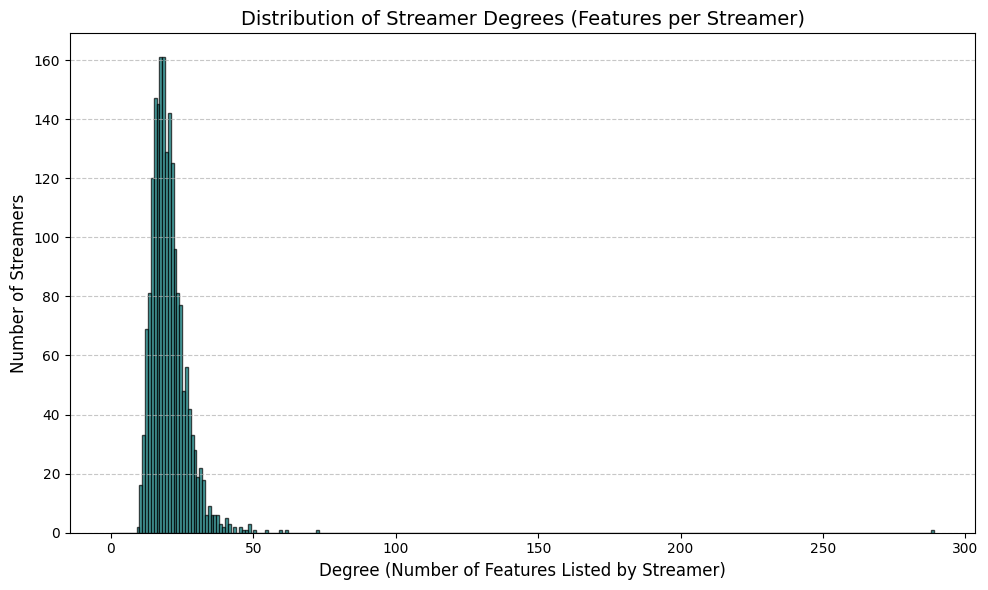

In [9]:
# Streamer Degrees in the 2-Mode Network
# Number of features each streamer lists (the other side of the 2-mode network)
streamer_degrees = pd.Series({n: B.degree(n) for n in streamer_nodes})
print(streamer_degrees.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

plt.figure(figsize=(10, 6))
plt.hist(
    streamer_degrees,
    bins=range(0, int(streamer_degrees.max()) + 2),
    color='teal',
    edgecolor='black',
    alpha=0.7,
)
plt.title("Distribution of Streamer Degrees (Features per Streamer)", fontsize=14)
plt.xlabel("Degree (Number of Features Listed by Streamer)", fontsize=12)
plt.ylabel("Number of Streamers", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

**Streamer Degree Distribution Summary**

* Most streamers list about the same number of features
  * This distribution is more bell-shaped. The typical streamer lists 19 features, and 80% of streamers list somewhere between 13 and 27. Nobody lists fewer than 9. There's one big outlier who lists 288 features, way more than anyone else (99% of streamers list 40 or fewer).
* This looks completely different from the feature side
  * Features were spread out across a very long tail, with most shared by almost no one and a few shared by nearly everyone. Streamers are the opposite: they're bunched tightly around the middle, apart from that one outlier.
* This sets up how the projection will behave
  * Every streamer lists at least 9 features, and the centerpoint features from above are shared by most of the community, so almost any two streamers will end up sharing something. Streamers who list more features will share more with everyone, so just having a bigger profile pulls a streamer toward the center of the projection. I check whether that holds once I get to the islands below.

## The First Group: Streamers

To see how streamers relate to each other, I'm projecting the 2-mode network onto just the streamers. Two streamers get connected if they share at least one feature, and the weight of that connection is the number of features they share. (People are linked through the groups they both belong to, with stronger links the more groups they share.)

In [10]:
# Project onto 1-Mode Streamer Graph
# (Shared Feature Weights)
# Edge weight = Number of shared games/features between two streamers
G_streamers = bipartite.weighted_projected_graph(B, streamer_nodes)
print(
    f"Projected 1-Mode Streamer Graph: {G_streamers.number_of_nodes()} nodes,"
    f" {G_streamers.number_of_edges()} weighted edges."
)

Projected 1-Mode Streamer Graph: 1912 nodes, 1738124 weighted edges.


count    1.738124e+06
mean     4.182913e+00
std      2.507124e+00
min      1.000000e+00
50%      4.000000e+00
80%      6.000000e+00
90%      8.000000e+00
95%      9.000000e+00
99%      1.200000e+01
max      3.400000e+01
dtype: float64


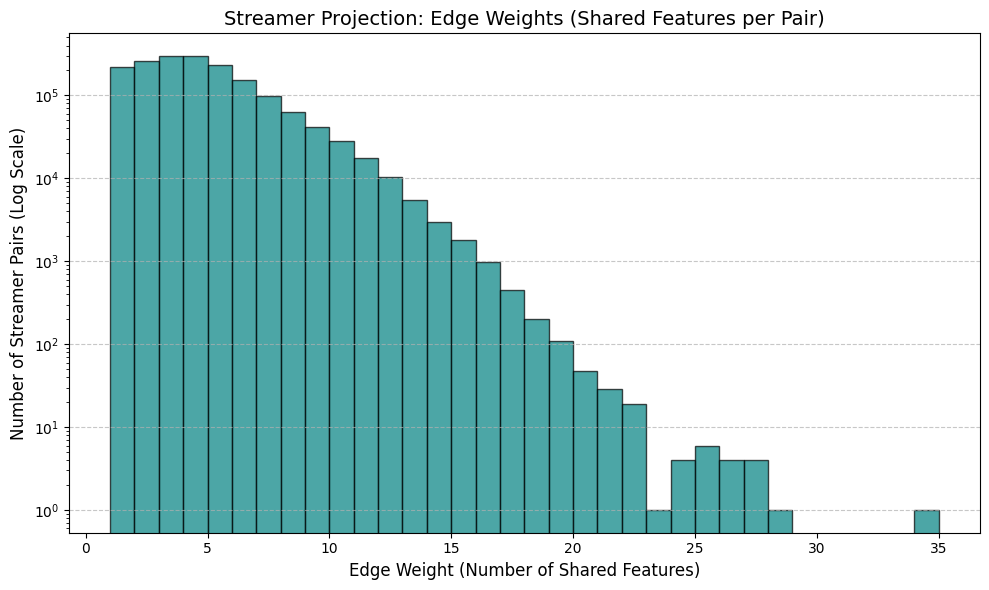

In [11]:
# Edge-Weight Distribution of the Streamer Projection
# Used to choose the "water level" for the island method (the book looks at this histogram first)
streamer_weights = pd.Series([d["weight"] for _, _, d in G_streamers.edges(data=True)])
print(streamer_weights.describe(percentiles=[0.5, 0.8, 0.9, 0.95, 0.99]))

plt.figure(figsize=(10, 6))
plt.hist(
    streamer_weights,
    bins=range(1, int(streamer_weights.max()) + 2),
    color="teal",
    edgecolor="black",
    alpha=0.7,
)
plt.yscale("log")
plt.title("Streamer Projection: Edge Weights (Shared Features per Pair)", fontsize=14)
plt.xlabel("Edge Weight (Number of Shared Features)", fontsize=12)
plt.ylabel("Number of Streamer Pairs (Log Scale)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Streamer Projection Edge-Weight Summary**

* Almost every streamer ends up connected to almost every other streamer
  * The projection has 1.7M connections out of 1.8M possible streamer pairs, so 95% of all pairs share at least one feature. Drawn as-is, the network would just be one giant tangled ball (the book calls this a "hairball").
* Most of these connections are weak
  * The typical pair of streamers shares only 4 features. Only 10% of pairs share more than 8 and only 1% share more than 12. On the histogram, the number of pairs drops off sharply once you get past about 10 shared features.
* This tells me where to start trimming for the Island Method
  * For the Island method, I'm looking at this histogram and choosing a cutoff, then dropping every connection weaker than that cutoff. So I'm going to test cutoffs from 1 to 25.

In [12]:
# Apply the Island Method for Size Reduction
# trim_edges is adapted from the book's island method code
# I'm keeping edges with weight >= the threshold (the book keeps >)
def trim_edges(g, weight=1):
  """Trims edges with weight less than the specified threshold (Island Method)."""
  g2 = nx.Graph()
  for u, v, data in g.edges(data=True):
    if data["weight"] >= weight:
      g2.add_edge(u, v, **data)
  for n in g.nodes():
    if n not in g2:
      g2.add_node(n)
  return g2


def island_sizes(g):
  """Sizes of the connected components (islands) once isolates are dropped, largest first."""
  active = [n for n in g.nodes() if g.degree(n) > 0]
  return sorted((len(c) for c in nx.connected_components(g.subgraph(active))), reverse=True)


print("\n--- Island Method Water-Level Breakdown (Streamers) ---")
thresholds = [1, 3, 5, 8, 10, 12, 15, 18, 20, 25]

for t in thresholds:
  sizes = island_sizes(trim_edges(G_streamers, weight=t))
  print(
      f"Threshold >= {t:2d} shared features | Active Streamers:"
      f" {sum(sizes):4d} | Connected Islands: {len(sizes):3d}"
      f" | Largest islands: {sizes[:8]}"
  )

# Select core threshold: the highest "meaningful" water level, i.e. high enough to cut
# the network down to its core, but not so high that the island disappears
core_threshold = 15  # Above the 99th-percentile edge weight (12); higher levels only shrink the same core
G_core = trim_edges(G_streamers, weight=core_threshold)
active_streamers = [n for n in G_core.nodes() if G_core.degree(n) > 0]
G_active = G_core.subgraph(active_streamers).copy()
islands = sorted(nx.connected_components(G_active), key=len, reverse=True)

print(
    f"\nCore Island Subgraph (Threshold >= {core_threshold}):"
    f" {G_active.number_of_nodes()} active nodes,"
    f" {G_active.number_of_edges()} edges,"
    f" {len(islands)} islands of sizes {[len(i) for i in islands]}."
)


--- Island Method Water-Level Breakdown (Streamers) ---
Threshold >=  1 shared features | Active Streamers: 1912 | Connected Islands:   1 | Largest islands: [1912]
Threshold >=  3 shared features | Active Streamers: 1912 | Connected Islands:   1 | Largest islands: [1912]
Threshold >=  5 shared features | Active Streamers: 1912 | Connected Islands:   1 | Largest islands: [1912]
Threshold >=  8 shared features | Active Streamers: 1826 | Connected Islands:   1 | Largest islands: [1826]
Threshold >= 10 shared features | Active Streamers: 1434 | Connected Islands:   5 | Largest islands: [1426, 2, 2, 2, 2]
Threshold >= 12 shared features | Active Streamers: 1030 | Connected Islands:   6 | Largest islands: [1020, 2, 2, 2, 2, 2]
Threshold >= 15 shared features | Active Streamers:  519 | Connected Islands:   5 | Largest islands: [511, 2, 2, 2, 2]
Threshold >= 18 shared features | Active Streamers:  184 | Connected Islands:   7 | Largest islands: [170, 3, 3, 2, 2, 2, 2]
Threshold >= 20 shared f

**Island Method Summary: Streamers**

* At low cutoffs, everyone is stuck together in one big island
  * Every streamer lists at least 9 features, and the centerpoint features are shared by most of the community, so almost every pair of streamers shares a few features without trying. As the book puts it (paraphrasing), sharing one group with someone is weak evidence of a real connection; it only starts to mean something once two people share a lot.
* Raising the cutoff shrinks the island instead of splitting it
  * A few tiny pieces break off (never more than 2–3 streamers each), but the main island just keeps getting smaller: from ~1.4K streamers at 10 shared features down to ~500 at 15 and under 100 by 20. The water is slowly drowning one big peak rather than revealing several.
* I set the cutoff at 15 shared features
  * This keeps only the strongest ~1% of connections and cuts the network from ~1.9K streamers and ~1.7M connections down to ~500 streamers and ~3.7K connections: one core plus four pairs. Going higher just shrinks the same core, and by 25 almost no one is left, which is what the book warns happens when you raise the water too high.

In [13]:
# Group Inferences (Partnered vs. Non-Partnered Streamers)
partner_map = target_df.set_index("new_id")["partner"].to_dict()
views_map = target_df.set_index("new_id")["views"].to_dict()

metrics = []
for node in G_active.nodes():
  user_id = int(node.replace("user_", ""))
  metrics.append({
      "user_id": user_id,
      "degree": G_active.degree(node),
      "weighted_degree": G_active.degree(node, weight="weight"),
      "partner": partner_map.get(user_id, False),
      "views": views_map.get(user_id, 0),
  })

metrics_df = pd.DataFrame(metrics)

print("\n--- Centrality Comparison: Partnered vs Non-Partnered ---")
group_summary = metrics_df.groupby("partner")[
    ["degree", "weighted_degree", "views"]
].agg(["mean", "median"])
group_summary.index = ["Not Partnered", "Partnered"]
print(group_summary.to_string())

# Welch's t-test (doesn't assume equal variances), following the Project 1 suggestion of a t-test.
# Degree and views are heavily skewed, so read these alongside the medians above.
print("\n--- Welch's t-test: Partnered vs Non-Partnered ---")
for col in ["degree", "weighted_degree", "views"]:
  t_stat, p_val = stats.ttest_ind(
      metrics_df.loc[metrics_df["partner"], col],
      metrics_df.loc[~metrics_df["partner"], col],
      equal_var=False,
  )
  print(f"{col:>15}: t = {t_stat:6.2f}, p = {p_val:.4f}")


--- Centrality Comparison: Partnered vs Non-Partnered ---
                  degree        weighted_degree                views           
                    mean median            mean median          mean     median
Not Partnered  15.152225    5.0      241.681499   81.0  3.140722e+04     8415.0
Partnered       9.782609    5.0      160.282609   77.0  3.764456e+06  1183567.0

--- Welch's t-test: Partnered vs Non-Partnered ---
         degree: t =  -3.17, p = 0.0017
weighted_degree: t =  -2.90, p = 0.0041
          views: t =   2.82, p = 0.0060


In [14]:
# Profile Each Streamer Island
# Size, partner share, median views, and the features most over-represented in the island
# (share of island members with the feature minus share of all streamers with it)
n_streamers = len(streamer_nodes)
overall_share = pd.Series({f: B.degree(f) / n_streamers for f in feature_nodes})
overall_partner_pct = 100 * target_df["partner"].mean()

island_rows = []
for i, island in enumerate(islands[:15], start=1):
  ids = [int(n.replace("user_", "")) for n in island]
  in_share = pd.Series([f for n in island for f in B.neighbors(n)]).value_counts() / len(island)
  lift = (in_share - overall_share.reindex(in_share.index)).sort_values(ascending=False)
  island_rows.append({
      "island": i,
      "streamers": len(island),
      "pct_partnered": round(100 * sum(partner_map.get(u, False) for u in ids) / len(ids), 1),
      "median_views": pd.Series([views_map.get(u, 0) for u in ids]).median(),
      "distinctive_features": ", ".join(lift.index[:5]),
  })

island_df = pd.DataFrame(island_rows)
print(f"Partnered streamers overall: {overall_partner_pct:.1f}%\n")
print(island_df.to_string(index=False))

Partnered streamers overall: 14.6%

 island  streamers  pct_partnered  median_views                                  distinctive_features
      1        511           18.0       11836.0   feat_2737, feat_2501, feat_83, feat_2424, feat_2549
      2          2            0.0        2478.0    feat_421, feat_1607, feat_1530, feat_928, feat_846
      3          2            0.0       11550.0 feat_1053, feat_1608, feat_2962, feat_1391, feat_1764
      4          2            0.0         692.0  feat_2530, feat_3155, feat_1144, feat_760, feat_1761
      5          2            0.0        9953.5  feat_1912, feat_3152, feat_1761, feat_1144, feat_760


In [15]:
# Features per Streamer: Core vs. Pairs vs. Streamers Below the Water Level
core_island = islands[0]
pair_islands = set().union(*islands[1:])
streamer_group = pd.Series({
    n: "1. core" if n in core_island else "2. pair" if n in pair_islands else "3. below water level"
    for n in streamer_nodes
})

print(f"--- Features per Streamer at Threshold >= {core_threshold} ---")
print(
    streamer_degrees.groupby(streamer_group)
    .describe()[["count", "mean", "25%", "50%", "75%", "min", "max"]]
    .to_string()
)

--- Features per Streamer at Threshold >= 15 ---
                       count       mean    25%   50%    75%   min    max
1. core                511.0  27.209393  22.50  25.0  29.00  18.0  288.0
2. pair                  8.0  23.000000  21.25  23.0  24.25  18.0   30.0
3. below water level  1393.0  17.179469  15.00  17.0  19.00   9.0   37.0


**What the Streamer Islands Tell Us**

* At the 15-feature cutoff, it's one core and a few stray pairs
  * ~510 of the ~520 streamers left are in one big core. The other four islands are pairs of streamers who share a lot with each other but not with anyone else.
* The core is made up of streamers with big profiles full of popular features
  * The features that show up more in the core than in the rest of the community (`feat_2737`, `feat_2501`, `feat_2424`) are all in the top 10 most common features. Core streamers also just list more features: ~25 for the typical core streamer vs ~17 for the streamers who got cut, and nobody in the core lists fewer than 18. So the core is partly a side effect of profile size: the more features you list, the more you share with everyone.
* The pairs are held together by rare features
  * Each pair is set apart by features outside the top 10 (like `feat_1053` and `feat_421`). Two of the pairs (islands 3 and 4) share three of those rare features, so they might be two separate pairs inside the same niche. None of the 8 streamers in the pairs is partnered.
* Partnered streamers are in the core, but not at the center of it
  * Partnered streamers make up 18.0% of the core vs 14.6% of everyone, so they show up there a bit more than you'd expect. On average they have fewer strong connections than non-partnered streamers (mean degree 9.8 vs 15.2; mean weighted degree 160 vs 242), and Welch's t-test says that difference is statistically significant (degree t = −3.17, p = 0.002; weighted degree t = −2.90, p = 0.004). But the medians are basically the same (degree 5 vs 5; weighted degree 77 vs 81). So the gap in the averages comes from a small group of very highly connected non-partnered streamers, not from the typical streamer.
* Views are where partners really stand apart
  * The typical partnered streamer has 1,183,567 views vs 8,415 for a non-partnered streamer (t = 2.82, p = 0.006), roughly 140 times more. Being partnered goes with audience size, not with how similar your profile is to everyone else's.
* Partners seem to cluster on one side of the core, but never split off
  * In the visualization below, partnered streamers (gold) look grouped on one side of the core instead of spread evenly through it. That's just what the layout shows, not a test, but it fits what the book calls status homophily: people with similar status tending to stick together. Partners never break off into their own island at any cutoff, so the core is held together mostly by shared games and habits, which the book calls value homophily (liking similar things).
* Caveat
  * These connections come from shared features, not actual friendships, so they measure how similar two streamers' profiles are. The high cutoff is what makes them more than weak evidence of a real connection.

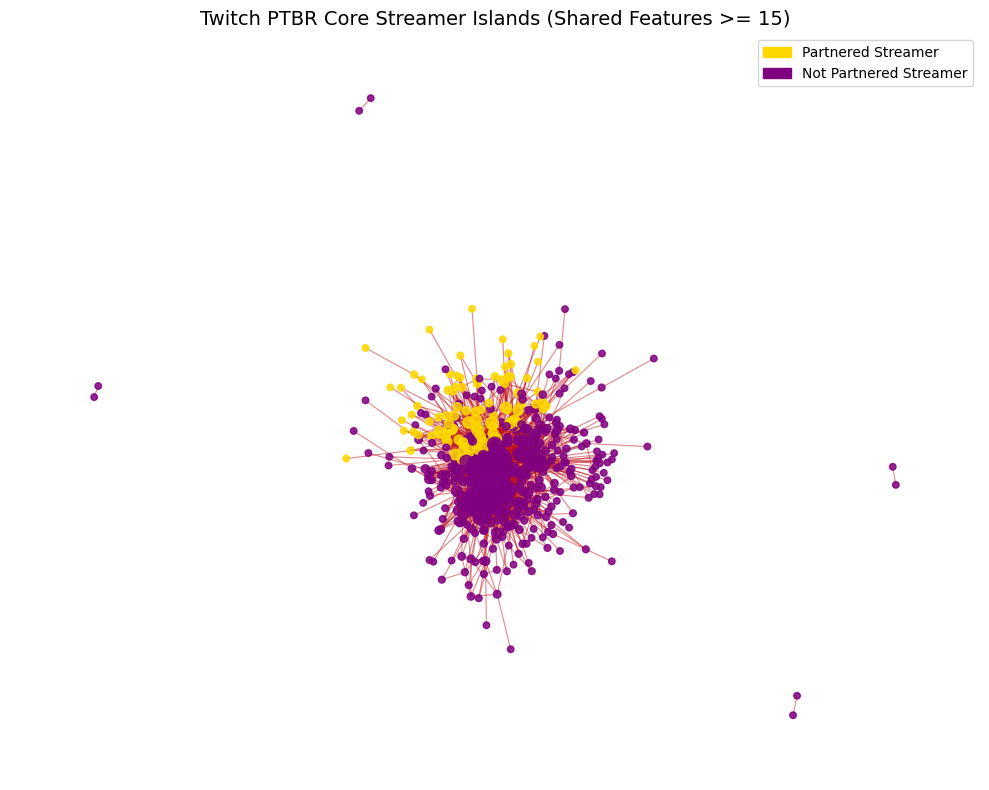

In [16]:
# Visualization
plt.figure(figsize=(10, 8))
plt.title(
    f"Twitch PTBR Core Streamer Islands (Shared Features >= {core_threshold})",
    fontsize=14,
)

pos = nx.spring_layout(G_active, seed=42, k=0.15)
node_colors = [
    "gold" if partner_map.get(int(n.replace("user_", "")), False) else "purple"
    for n in G_active.nodes()
]
node_sizes = [20 + G_active.degree(n) * 2 for n in G_active.nodes()]

nx.draw_networkx_nodes(
    G_active, pos, node_size=node_sizes, node_color=node_colors, alpha=0.85
)
# Edge width and color by log(weight), as the book does
edge_log_weights = [math.log(d["weight"]) for _, _, d in G_active.edges(data=True)]
nx.draw_networkx_edges(
    G_active,
    pos,
    width=[0.3 * w for w in edge_log_weights],
    edge_color=edge_log_weights,
    edge_cmap=plt.cm.Reds,
    edge_vmin=0,  # Start the color scale at weight 1 so the weakest kept edges aren't white
    alpha=0.5,
)

legend_handles = [
    mpatches.Patch(color="gold", label="Partnered Streamer"),
    mpatches.Patch(color="purple", label="Not Partnered Streamer"),
]
plt.legend(handles=legend_handles, loc="upper right")

plt.axis("off")
plt.tight_layout()
plt.show()

## The Second Group: Features

The prompt asks what we can infer about *each* distinct group. So, following the book, I project the network the other way as well: what the book calls an "inverse affiliation network": features linked through the streamers who share them. This mirrors the book's PAC and candidate example, where it projects the network both ways. The edge weight is the number of streamers who list both features. The feature IDs are anonymized (SNAP describes them as derived from games played and liked, location, and streaming habits), so the inferences below are about structure rather than named games.

Projected 1-Mode Feature Graph: 1449 nodes, 109450 weighted edges.
count    109450.000000
mean          3.932947
std          17.312376
min           1.000000
50%           1.000000
80%           3.000000
90%           6.000000
95%          12.000000
99%          52.000000
max        1305.000000
dtype: float64


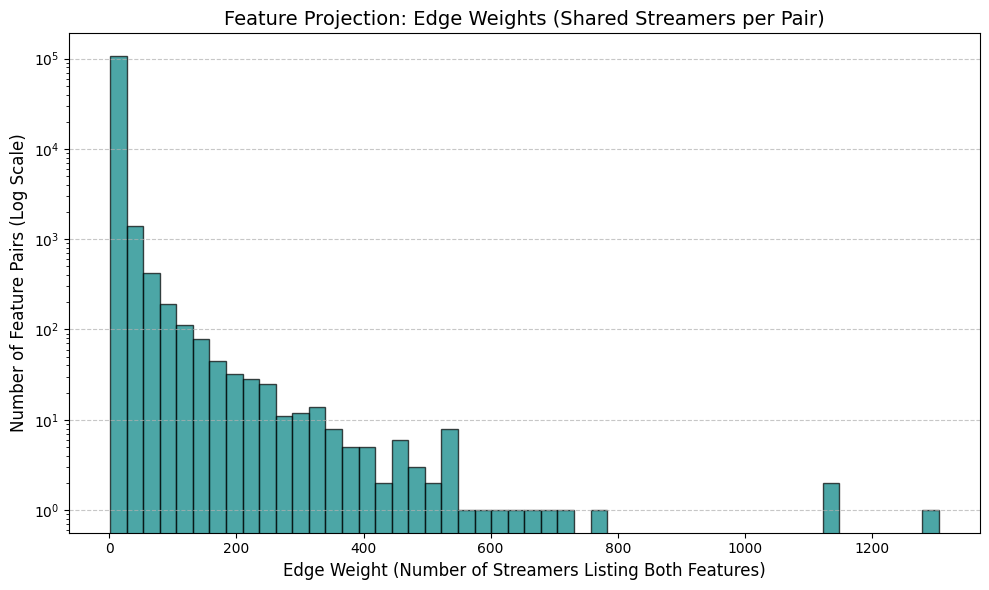

In [17]:
# Project onto 1-Mode Feature Graph
# Edge weight = Number of streamers who list both features
G_features = bipartite.weighted_projected_graph(B, feature_nodes)
print(
    f"Projected 1-Mode Feature Graph: {G_features.number_of_nodes()} nodes,"
    f" {G_features.number_of_edges()} weighted edges."
)

feature_weights = pd.Series([d["weight"] for _, _, d in G_features.edges(data=True)])
print(feature_weights.describe(percentiles=[0.5, 0.8, 0.9, 0.95, 0.99]))

plt.figure(figsize=(10, 6))
plt.hist(feature_weights, bins=50, color="teal", edgecolor="black", alpha=0.7)
plt.yscale("log")
plt.title("Feature Projection: Edge Weights (Shared Streamers per Pair)", fontsize=14)
plt.xlabel("Edge Weight (Number of Streamers Listing Both Features)", fontsize=12)
plt.ylabel("Number of Feature Pairs (Log Scale)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [18]:
# Apply the Island Method to the Feature Graph
print("\n--- Island Method Water-Level Breakdown (Features) ---")
feature_thresholds = [1, 2, 3, 5, 10, 25, 50, 100, 200, 400]

for t in feature_thresholds:
  sizes = island_sizes(trim_edges(G_features, weight=t))
  print(
      f"Threshold >= {t:3d} shared streamers | Active Features:"
      f" {sum(sizes):4d} | Connected Islands: {len(sizes):3d}"
      f" | Largest islands: {sizes[:8]}"
  )

feature_core_threshold = 200  # Highest level with more than one island (at >= 400 only the 14-feature core remains)
G_feat_core = trim_edges(G_features, weight=feature_core_threshold)
active_features = [n for n in G_feat_core.nodes() if G_feat_core.degree(n) > 0]
G_feat_active = G_feat_core.subgraph(active_features).copy()
feature_islands = sorted(nx.connected_components(G_feat_active), key=len, reverse=True)

print(
    f"\nCore Feature Islands (Threshold >= {feature_core_threshold}):"
    f" {G_feat_active.number_of_nodes()} active features,"
    f" {G_feat_active.number_of_edges()} edges,"
    f" {len(feature_islands)} islands of sizes {[len(i) for i in feature_islands]}."
)


--- Island Method Water-Level Breakdown (Features) ---
Threshold >=   1 shared streamers | Active Features: 1449 | Connected Islands:   1 | Largest islands: [1449]
Threshold >=   2 shared streamers | Active Features:  874 | Connected Islands:   1 | Largest islands: [874]
Threshold >=   3 shared streamers | Active Features:  658 | Connected Islands:   1 | Largest islands: [658]
Threshold >=   5 shared streamers | Active Features:  483 | Connected Islands:   1 | Largest islands: [483]
Threshold >=  10 shared streamers | Active Features:  358 | Connected Islands:   2 | Largest islands: [356, 2]
Threshold >=  25 shared streamers | Active Features:  234 | Connected Islands:   3 | Largest islands: [230, 2, 2]
Threshold >=  50 shared streamers | Active Features:  141 | Connected Islands:   1 | Largest islands: [141]
Threshold >= 100 shared streamers | Active Features:   74 | Connected Islands:   2 | Largest islands: [72, 2]
Threshold >= 200 shared streamers | Active Features:   45 | Connecte

In [19]:
# Profile Each Feature Island
# Its most-listed features, how many streamers carry at least one of them, and those streamers' partner share
feature_rows = []
for i, island in enumerate(feature_islands[:15], start=1):
  carriers = {s for f in island for s in B.neighbors(f)}
  carrier_ids = [int(s.replace("user_", "")) for s in carriers]
  feature_rows.append({
      "island": i,
      "features": len(island),
      "streamers_with_any": len(carriers),
      "pct_partnered": round(
          100 * sum(partner_map.get(u, False) for u in carrier_ids) / len(carrier_ids), 1
      ),
      "top_features": ", ".join(sorted(island, key=B.degree, reverse=True)[:6]),
  })

feature_df = pd.DataFrame(feature_rows)
print(f"Partnered streamers overall: {overall_partner_pct:.1f}%\n")
print(feature_df.to_string(index=False))

Partnered streamers overall: 14.6%

 island  features  streamers_with_any  pct_partnered                                                  top_features
      1        42                1912           14.6 feat_920, feat_224, feat_3097, feat_569, feat_2645, feat_2424
      2         3                 279          100.0                                feat_2814, feat_119, feat_1644


In [20]:
# Check: Does the 3-Feature Island Line Up Exactly with Partner Status?
partner_feature_island = feature_islands[1]
print("Features in island 2:", sorted(partner_feature_island))

has_partner_feature = pd.Series({
    int(n.replace("user_", "")): any(B.has_edge(n, f) for f in partner_feature_island)
    for n in streamer_nodes
})
partner_status = pd.Series(partner_map).reindex(has_partner_feature.index)

print(pd.crosstab(
    has_partner_feature.rename("Has any of the 3 features"),
    partner_status.rename("Partnered"),
))

Features in island 2: ['feat_119', 'feat_1644', 'feat_2814']
Partnered                  False  True 
Has any of the 3 features              
False                       1633      0
True                           0    279


### Checking the Partner Features

The crosstab is perfectly diagonal. All 279 partnered streamers have at least one of `feat_119`, `feat_1644` and `feat_2814`, and none of the 1,633 non-partnered streamers have any of them. So these three features encode partner status exactly: they are a direct label rather than an inferred pattern. This also confirms that comparing partners on feature similarity is partly circular (see the caveat in the streamer section). The next check shows that the same is true on the non-partner side.

In [21]:
# Check: Do the Two Biggest Hubs (feat_920, feat_224) Line Up with Partner Status?
for hub in ["feat_920", "feat_224"]:
  has_hub = pd.Series({
      int(n.replace("user_", "")): B.has_edge(n, hub) for n in streamer_nodes
  })
  print(f"\n--- {hub} ---")
  print(pd.crosstab(
      has_hub.rename(f"Has {hub}"),
      partner_status.reindex(has_hub.index).rename("Partnered"),
  ))


--- feat_920 ---
Partnered     False  True 
Has feat_920              
False             0    279
True           1633      0

--- feat_224 ---
Partnered     False  True 
Has feat_224              
False           328    279
True           1305      0


### Checking the Biggest Hubs

Both crosstabs show that the two biggest hubs are also about partner status, not games or habits:

* **`feat_920` is a "not partnered" label.** All 1,633 non-partnered streamers have it, and none of the 279 partnered streamers do. So its 85% reach just reflects that 85% of streamers aren't partners.
* **`feat_224` only appears for non-partnered streamers.** 1,305 of the 1,633 non-partnered streamers have it, and no partnered streamer does. It may be a second status-related label, or a feature that only non-partners have; the anonymized IDs don't say which.
* **What this changes.** Partner status is encoded on both sides: three features mark partners, and `feat_920` marks everyone else. This is why the 3-feature partner island separates from the core: the partner features never co-occur with `feat_920` or `feat_224`, the two biggest features in the core. It also means part of the hub structure in both projections reflects status rather than shared interests.

**What the Feature Islands Tell Us**

* Most feature pairs only show up together once
  * The feature projection has ~110K connections out of ~1M possible pairs (~10%). Half of those connections come from just one streamer who happens to list both features.
* The heaviest connection is between the two non-partner features
  * `feat_920` and `feat_224` share ~1.3K streamers, the strongest link in the whole feature network. Every streamer who lists `feat_224` also lists `feat_920`, which makes sense given the checks above: `feat_920` marks every non-partnered streamer, and `feat_224` only shows up for non-partnered streamers.
* Just like the streamers, the features form one core that shrinks instead of splitting
  * Raising the cutoff takes the core from ~1.4K features down to under 900 (almost all of the ones that drop out are features only one streamer lists), then to ~140, and finally to just 14 features at the highest cutoff.
* Small clusters pop up but don't last
  * At low cutoffs a couple of 2-feature islands break off, but they're gone again by 50 shared streamers. At 200 shared streamers (the highest cutoff with more than one island, and the one I use for the profile above), a 3-feature island splits away from a 42-feature core.
* That 3-feature island is partner status
  * Every streamer who has any of `feat_119`, `feat_2814` or `feat_1644` is partnered, and the crosstab above shows every partnered streamer has at least one of them. These three break off as their own island because they show up together a lot but never alongside `feat_920` or `feat_224`, which only non-partnered streamers have. Meanwhile, the 42-feature core is shared by all ~1.9K streamers and has the same ~15% partner rate as the community overall.

## Conclusions: What Can We Infer About Each Group?

### Streamers

* The streamers form one big core with a periphery around it, not separate communities
  * Streamers end up in the core by listing lots of features, especially popular ones, so the core is partly a side effect of profile size. Partner status shapes the core a little (partners show up there a bit more and look grouped on one side), but partners never split off into an island of their own.

### Features

* A few features are listed by a huge number of streamers, while most features barely connect to anything
  * The biggest centerpoint features turned out to be partner-status labels rather than games or habits, and the only separate feature island was partner status too. Beyond those, a small set of widely shared features ties the community together, while about 40% of features belong to just one streamer.

### How the Two Groups Shape Each Other

* The two sides mirror each other
  * The b book called this something like the duality of persons and groups. The streamer core exists because of the feature core: core streamers are set apart by the most common features, while the pairs on the edge are held together by rare ones.

### Reducing the Network

* The island method shrank the network but couldn't split it
  * Raising the cutoff to 15 shared features cut the streamer network from ~1.9K streamers and ~1.7M connections down to ~500 streamers and ~3.7K connections. But instead of revealing several separate islands, it just kept shrinking one core. That's the main finding in itself: this community doesn't divide into subgroups based on what streamers list.

### Limitations

* The features are anonymized
* These are similarity connections, not friendships since streamers are connected by the features they share, not by who actually follows whom.
* Partner status is built into the features on both sides, making comparing partners on feature similarity slightly circular.